# The pathways and fate of Italian coastal plastic pollution
In this example, we will use `plasticparcels` to run a basic simulation of microplastic pollution along the Italian coastline. We will use the [Coastal mismanaged plastic waste emissions dataset](https://plastic.parcels-code.org/en/latest/initialisationmaps.html) to release virtual particles in coastal model grid cells, using the 2D surface velocity fields to advect the particles. We also include the effects of Stokes drift and wind-induced drift on the particles, but neglect any vertical motion (along with any biofouling, or vertical mixing).

In [ ]:
# Library imports
from datetime import datetime, timedelta

# parcels and plasticparcels imports
import plasticparcels as pp

# Plotting imports
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

## Load settings
We first load in the model settings, and define the simulation settings. For this simulation, we will release the particles at midnight on January 1st 2024. The particle trajectories will be 60 days long, saving the their position every 12 hours. We also set the advection timestep to 20 minutes. By default `plasticparcels` uses 3D advection, so we turn off the 3D-mode, as well as the biofouling behaviour. We ensure that the Stokes drift behaviour and wind-induced drift behaviour is on.

We will also download the necessary release location files (if they are not already downloaded).

In [2]:
# Load the model settings
settings_file = 'copernicus_marine.json'
settings = pp.utils.load_settings(settings_file)

# Download the mask and release data
settings = pp.utils.download_plasticparcels_dataset('NEMO0083', settings, 'input_data')


/Users/erik/Codes/plasticparcels/plasticparcels/utils.py:168: UserWarning: Could not set settings path ('unbeaching', 'filename') for dataset 'NEMO0083'.
  warnings.warn(f"Could not set settings path {settings_path} for dataset {dataset!r}.", stacklevel=1)


In [3]:
# Create the simulation settings
settings['simulation'] = {
    'startdate': datetime(2024, 1, 1),       # Start date of simulation
    'runtime': timedelta(days=60),           # Runtime of simulation
    'outputdt': timedelta(hours=12),         # Timestep of output
    'dt': timedelta(minutes=20),             # Timestep of advection

    # Specific to copernicusmarine datasets, provide a bounding box and depth range for your simulation
    'boundingbox': [ 3.0, 25.0, 30.0, 46.0], # Bounding box of simulation [lonmin, lonmax, latmin, latmax]}
    'depth_range': [0, 1],                   # Depth range of simulation [depthmin, depthmax] in meters
}

# Overwrite some settings
settings['use_3D'] = False
settings['use_biofouling'] = False
settings['use_stokes'] = True
settings['use_wind'] = True


Next, we define our release settings and plastic particle type. In this example we will use the `coastal` release type (see [here](https://plastic.parcels-code.org/en/latest/initialisationmaps.html) for more detail), selecting only release locations along the Italian coastline. We will simulate the pathways of plastic particles that at 0.1mm, and will apply a wind coefficient of 1%. We give the plastic particles a denisity of 1030 kg/m<sup>3</sup>, however, since this is an ocean-surface only simulation, this parameter will have no impact on our simulation.

In [4]:
# Create the particle release settings
settings['release'] = {
    'initialisation_type': 'coastal',
    'country': 'Italy',
}

In [5]:
# Create the plastic type settings
settings['plastictype'] = {
    'wind_coefficient' : 0.01,  # Percentage of wind to apply to particles
    'plastic_diameter' : 0.001, # Plastic particle diameter (m)
    'plastic_density' : 1030.,  # Plastic particle density (kg/m^3)
}

## Create a `FieldSet`, `ParticleSet` and `Kernel` list
Here we create the necessary `Parcels` objects to run our simulation. The `FieldSet` contains all the hydrodynamic, wind, and wave data required for our simulation. The `ParticleSet` is a set of particles initialised along the Italian coastline, and the `Kernel` list is a list of kernels that will be applied to these particles. A useful overview of these `Parcels` objects can be found [here](https://docs.parcels-code.org/en/latest/examples/tutorial_parcels_structure.html).

In [6]:
# Create the fieldset
fieldset = pp.constructors.create_fieldset(settings)

# Create the particleset
pset = pp.constructors.create_particleset_from_map(fieldset, settings)

# Create the applicable kernels to the plastic particles
kernels = pp.constructors.create_kernel(fieldset)

INFO - 2026-11-13T07:20:58Z - Selected dataset version: "202406"
INFO - 2026-11-13T07:20:58Z - Selected dataset part: "default"
WARNING - 2026-11-13T07:20:58Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
INFO - 2026-11-13T07:21:00Z - Selected dataset version: "202406"
INFO - 2026-11-13T07:21:00Z - Selected dataset part: "default"
WARNING - 2026-11-13T07:21:00Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
INFO - 2026-11-13T07:21:01Z - Selected dataset version: "202406"
INFO - 2026-11-13T07:21:01Z - Selected dataset part: "default"
WARNING - 2026-11-13T07:21:01Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
INFO - 2026-11-13T07:21:03Z - Selected dataset version: "202406"
INFO - 2026-11-13T07:21:03Z - Selected dataset 

INFO: No depth dimension found in dataset. Added a singleton depth dimension.


INFO - 2026-11-13T07:21:17Z - Selected dataset version: "202411"
INFO - 2026-11-13T07:21:17Z - Selected dataset part: "default"
INFO - 2026-11-13T07:21:19Z - Selected dataset version: "202411"
INFO - 2026-11-13T07:21:19Z - Selected dataset part: "default"
INFO - 2026-11-13T07:21:20Z - Selected dataset version: "202411"
INFO - 2026-11-13T07:21:20Z - Selected dataset part: "default"


INFO: No depth dimension found in dataset. Added a singleton depth dimension.


INFO - 2026-11-13T07:21:22Z - Selected dataset version: "202211"
INFO - 2026-11-13T07:21:22Z - Selected dataset part: "default"
INFO - 2026-11-13T07:21:24Z - Selected dataset version: "202211"
INFO - 2026-11-13T07:21:24Z - Selected dataset part: "default"


INFO: No depth dimension found in dataset. Added a singleton depth dimension.


Define the runtime, the timestepping, and the output frequency of the simulation from the settings.

In [7]:
runtime = settings['simulation']['runtime']
dt = settings['simulation']['dt']
outputdt = settings['simulation']['outputdt']

## Run the simulation
To run the simulation we create a `ParticleFile` that will store the trajectory information of all particles at the specified output timestep. We then `execute` the simulation with the specified runtime and timestepping.

In [8]:
# Create the particle file where output will be stored
pfile = pp.ParticleFile('example_Italy_coast.parquet', settings=settings, outputdt=outputdt, mode="w")

In [9]:
# Execute the simulation
pset.execute(kernels, runtime=runtime, dt=dt, output_file=pfile)

INFO: Output files are stored in example_Italy_coast.parquet
Integration time: 2024-02-29T12:00:00 100%|██████████| [01:00<00:00, 85713.98it/s] 


## Plot the trajectories
Finally, we produce a simple 'spaghetti' plot and and a concentration map of the trajectories to visualise their pathways. To understand how to work with `PlasticParcels` output, please see the `Parcels` tutorial [here](https://docs.parcels-code.org/en/latest/examples/tutorial_output.html).

/Users/erik/Codes/plasticparcels/.pixi/envs/default/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/erik/Codes/plasticparcels/.pixi/envs/default/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/erik/Codes/plasticparcels/.pixi/envs/default/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


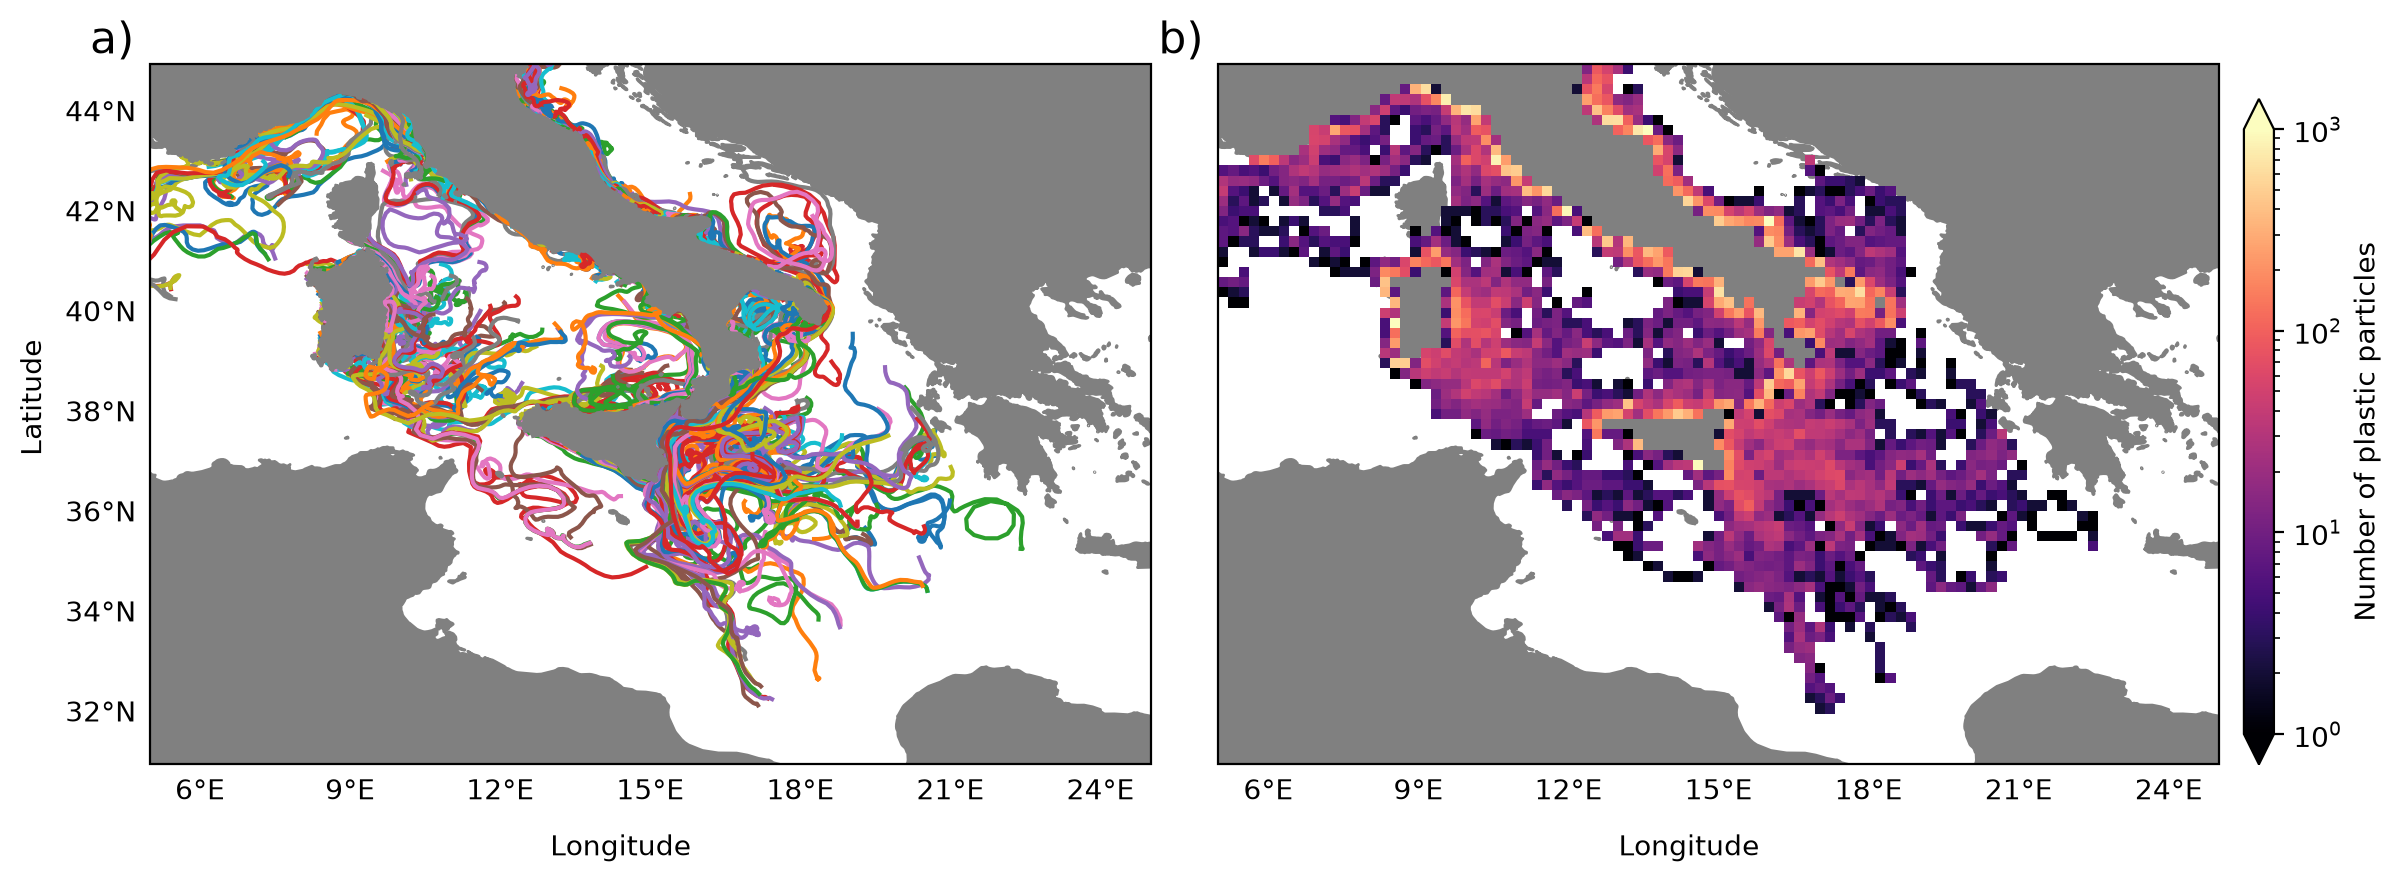

In [10]:
# Load the ParticleFile
df = pp.read_particlefile('example_Italy_coast.parquet')

# Settings for the concentration map
bins = (np.linspace(5,25,100),np.linspace(31,45,70))
i = -1 # Use final timestep

# Create the figure object
plt.figure(figsize=(14,5), dpi=200)
gs = gridspec.GridSpec(1, 3, width_ratios=[30,30,1], wspace=0.1)
cb_axes_position = [1.025, 0.0, 0.03, 0.95]

# Plot the trajectories
ax = plt.subplot(gs[0,0], projection=ccrs.PlateCarree())
for traj in df.partition_by("particle_id", maintain_order=True):
    ax.plot(traj["x"], traj["y"], "-", transform=ccrs.PlateCarree(), zorder=0)
ax.add_feature(cfeature.LAND, zorder=0, color='grey')

ax.set_extent([5,25,31,45], crs=ccrs.PlateCarree())
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False,color = "None")
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator([6,9,12,15,18,21,24])

ax.text(-0.06, 1.015, 'a)', transform=ax.transAxes, size=16)
ax.text(-0.13, 0.45, 'Latitude', transform=ax.transAxes, size=10, rotation=90)
ax.text(0.4, -0.13, 'Longitude', transform=ax.transAxes, size=10)

# Plot the Concentration map
ax = plt.subplot(gs[0,1], projection=ccrs.PlateCarree())
cb = ax.hist2d(df["x"], df["y"], bins=bins,norm=LogNorm(vmin=1, vmax=1000), cmap=plt.cm.magma, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, zorder=0, color='grey')

cbar_ax = ax.inset_axes(cb_axes_position)
cbar = plt.colorbar(cb[3], cax=cbar_ax, extend='both')
cbar.set_label('Number of plastic particles', fontsize=10)
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False,color = "None")
gl.top_labels = False
gl.right_labels = False
gl.left_labels = False
gl.xlocator = mticker.FixedLocator([6,9,12,15,18,21,24])

ax.text(-0.06, 1.015, 'b)', transform=ax.transAxes, size=16)
ax.text(0.4, -0.13, 'Longitude', transform=ax.transAxes, size=10)

plt.show()